<a href="https://colab.research.google.com/github/natuckstack/PFI/blob/main/PFI1eraparte.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Option A: Mount Google Drive (Click play manually and accept the permissions popup)
from google.colab import drive
try:
    drive.mount('/content/drive', force_remount=True)
    print("Drive mounted successfully!")
except Exception as e:
    print(f"Could not mount Drive: {e}")
    print("\nOption B: Upload files manually from your local computer below:")
    from google.colab import files
    uploaded = files.upload()

Mounted at /content/drive
Drive mounted successfully!


In [ ]:
import pandas as pd
from google.colab import auth
import gspread
from google.auth import default

# Authenticate and create the gspread client
auth.authenticate_user()
creds, _ = default()
gc = gspread.authorize(creds)

# Open the 'Estados Financieros PFI' Google Sheet by name
sheet_name = 'Estados Financieros PFI'
target_worksheet = ' Gastos operativos detallados'

try:
    # Open the spreadsheet
    spreadsheet = gc.open(sheet_name)

    # Get all worksheet titles to debug and find a matching one
    worksheets = spreadsheet.worksheets()
    worksheet_titles = [ws.title for ws in worksheets]
    print("Available worksheets in this file:", worksheet_titles)

    # Try to find a match ignoring leading/trailing whitespaces and case
    matched_title = None
    for title in worksheet_titles:
        if title.strip().lower() == target_worksheet.strip().lower():
            matched_title = title
            break

    if matched_title:
        print(f"Found matching worksheet: '{matched_title}'")
        worksheet = spreadsheet.worksheet(matched_title)
    else:
        print(f"Could not find an exact match for '{target_worksheet}'. Loading the first sheet as fallback.")
        worksheet = spreadsheet.get_worksheet(0)

    data = worksheet.get_all_values()

    # Load into a pandas DataFrame
    df_sheet = pd.DataFrame(data[1:], columns=data[0])
    print(f"Successfully loaded worksheet as a DataFrame!")
    display(df_sheet.head())
except Exception as e:
    print(f"Error loading Google Sheet '{sheet_name}': {e}")

Available worksheets in this file: ['Situación Patrimonial', 'Ganancias y Pérdidas', 'Evolución Patrimonio', 'Flujo de Efectivo', 'Gastos Operativos Detallados']
Found matching worksheet: 'Gastos Operativos Detallados'
Successfully loaded worksheet as a DataFrame!


,BANCO DE CRÉDITO DE BOLIVIA S.A.,,,,
0,DETALLE INTEGRAL DE COSTOS Y GASTOS OPERATIVOS,,,,
1,Ejercicios terminados al 31 de diciembre de 20...,,,,
2,CATEGORÍA,CONCEPTO / SUBCUENTA,NOTA,2025 (Bs),2024 (Bs)
3,Otros Gastos Operativos,Comisiones por servicios,8 t) (ii),"54,988,166","83,634,163"
4,- Detalle comisiones,Comisiones diversas,8 t) (ii),"28,503,760","67,274,744"


In [ ]:
# Make a copy of the raw dataframe
df_cleaned = df_sheet.copy()

# The actual headers are in the 3rd row (index 2)
new_header = df_cleaned.iloc[2]

# Remove the first 3 rows (metadata and the header row itself)
df_cleaned = df_cleaned[3:]

# Set the new headers
df_cleaned.columns = new_header
df_cleaned.columns = df_cleaned.columns.str.strip()

# Define the target comparison columns
col_2025 = '2025 (Bs)'
col_2024 = '2024 (Bs)'

# Remove commas and convert the financial columns to numeric values
for col in [col_2025, col_2024]:
    if col in df_cleaned.columns:
        df_cleaned[col] = df_cleaned[col].astype(str).str.replace(',', '', regex=False)
        df_cleaned[col] = pd.to_numeric(df_cleaned[col], errors='coerce')

# Drop rows where both 2024 and 2025 data are NaN (meaning they aren't data rows we can compare)
df_cleaned = df_cleaned.dropna(subset=[col_2025, col_2024], how='all')

# Reset index for a clean dataframe
df_cleaned = df_cleaned.reset_index(drop=True)

print("Cleaned DataFrame ready for 2024/2025 comparison:")
display(df_cleaned.head(15))

Cleaned DataFrame ready for 2024/2025 comparison:


2,CATEGORÍA,CONCEPTO / SUBCUENTA,NOTA,2025 (Bs),2024 (Bs)
0,Otros Gastos Operativos,Comisiones por servicios,8 t) (ii),5.498817e+07,83634163.0
1,- Detalle comisiones,Comisiones diversas,8 t) (ii),2.850376e+07,67274744.0
2,- Detalle comisiones,Comisiones cámara de compensación,8 t) (ii),2.549602e+07,14781619.0
3,- Detalle comisiones,"Comisiones por giros, transferencias y órden...",8 t) (ii),9.883890e+05,1577800.0
4,Otros Gastos Operativos,Costos de bienes realizables,8 t),4.663016e+07,56750335.0
5,Otros Gastos Operativos,Pérdidas por inversiones permanentes no financ...,8 t),8.740120e+05,257645.0
6,Gastos Operativos Diversos,Pérdidas por operaciones de cambio y arbitraje,8 t),1.761322e+09,866020787.0
7,Gastos Operativos Diversos,Contingencias futuras riesgo operativo,8 t),7.707210e+07,36358000.0
8,Gastos Operativos Diversos,Uso de Marca BCP,8 t),2.006318e+07,18808397.0
9,Gastos Operativos Diversos,Outsourcing ATC,8 t),1.971094e+07,22741698.0


In [ ]:
# Group the data by CATEGORÍA and sum the financial columns
category_grouped = df_cleaned.groupby('CATEGORÍA')[[col_2024, col_2025]].sum().reset_index()

# Calculate Absolute Growth and Percentage Growth
category_grouped['Absolute Growth (Bs)'] = category_grouped[col_2025] - category_grouped[col_2024]
category_grouped['Percentage Growth (%)'] = (category_grouped['Absolute Growth (Bs)'] / category_grouped[col_2024]) * 100

# Sort by Absolute Growth descending to get the top 5
top_5_growth = category_grouped.sort_values(by='Absolute Growth (Bs)', ascending=False).head(5)

print("Top 5 Expense Categories with the Highest Absolute Growth (2024 to 2025):")
display(top_5_growth)

Top 5 Expense Categories with the Highest Absolute Growth (2024 to 2025):


2,CATEGORÍA,2024 (Bs),2025 (Bs),Absolute Growth (Bs),Percentage Growth (%)
7,TOTAL COSTOS Y GASTOS OPERATIVOS,1.878756e+09,2.886520e+09,1.007764e+09,53.639978
2,Gastos Operativos Diversos,1.034508e+09,1.955130e+09,9.206218e+08,88.991286
6,SUBTOTAL OTROS GASTOS OPERATIVOS,1.175150e+09,2.057622e+09,8.824720e+08,75.094416
5,SUBTOTAL GASTOS DE ADMINISTRACIÓN,7.036058e+08,8.288980e+08,1.252922e+08,17.807157
1,GASTOS DE ADMINISTRACIÓN,5.173186e+08,6.198801e+08,1.025615e+08,19.825603


/tmp/ipykernel_752/4278609079.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


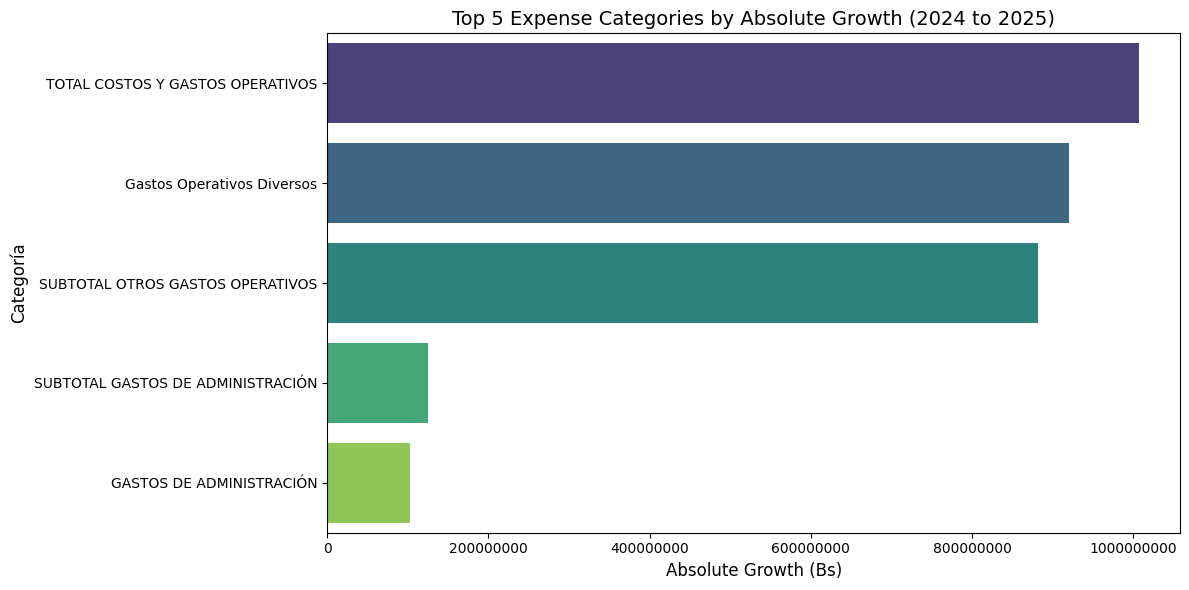

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set the figure size
plt.figure(figsize=(12, 6))

# Create a horizontal bar chart
sns.barplot(
    data=top_5_growth,
    x='Absolute Growth (Bs)',
    y='CATEGORÍA',
    palette='viridis'
)

# Add titles and labels
plt.title('Top 5 Expense Categories by Absolute Growth (2024 to 2025)', fontsize=14)
plt.xlabel('Absolute Growth (Bs)', fontsize=12)
plt.ylabel('Categoría', fontsize=12)

# Format the x-axis to show millions/billions cleanly
plt.ticklabel_format(style='plain', axis='x')

plt.tight_layout()
plt.show()

In [ ]:
# Calculate growth at the individual row level
df_details = df_cleaned.copy()
df_details['Absolute Growth (Bs)'] = df_details[col_2025] - df_details[col_2024]

# Clean the sub-account column
df_details['CONCEPTO / SUBCUENTA'] = df_details['CONCEPTO / SUBCUENTA'].fillna('').astype(str).str.strip()

# Filter out empty rows and aggregate/subtotal rows (e.g., containing "Total" or "+")
sub_accounts = df_details[
    (df_details['CONCEPTO / SUBCUENTA'] != '') &
    (~df_details['CONCEPTO / SUBCUENTA'].str.contains(r'Total|\+', case=False, na=False))
]

# Get the top 10 individual sub-accounts with the highest absolute growth
top_sub_accounts = sub_accounts.sort_values(by='Absolute Growth (Bs)', ascending=False).head(10)

# Merge with the category totals we calculated previously
comparison_df = top_sub_accounts.merge(
    category_grouped[['CATEGORÍA', 'Absolute Growth (Bs)']],
    on='CATEGORÍA',
    suffixes=('_SubAccount', '_CategoryTotal')
)

# Calculate how much the sub-account contributed to the category's overall growth
comparison_df['% of Category Growth'] = (comparison_df['Absolute Growth (Bs)_SubAccount'] / comparison_df['Absolute Growth (Bs)_CategoryTotal']) * 100

print("Top Sub-accounts vs Their Category's Total Growth (Filtered for Individual Items):")
display(comparison_df[['CATEGORÍA', 'CONCEPTO / SUBCUENTA', 'Absolute Growth (Bs)_SubAccount', 'Absolute Growth (Bs)_CategoryTotal', '% of Category Growth']])

Top Sub-accounts vs Their Category's Total Growth (Filtered for Individual Items):


2,CATEGORÍA,CONCEPTO / SUBCUENTA,Absolute Growth (Bs)_SubAccount,Absolute Growth (Bs)_CategoryTotal,% of Category Growth
0,Gastos Operativos Diversos,Pérdidas por operaciones de cambio y arbitraje,895301443.0,920621777.0,97.249649
1,Gastos Operativos Diversos,Contingencias futuras riesgo operativo,40714100.0,920621777.0,4.422457
2,GASTOS DE ADMINISTRACIÓN,"Gastos de personal (ejecutivo, directores y pe...",38517241.0,102561521.0,37.555255
3,GASTOS DE ADMINISTRACIÓN,Impuestos,35491971.0,102561521.0,34.605543
4,Otros Gastos de Administración,Aportes al Fondo de Protección al Ahorrista,18933423.0,22730664.0,83.294632
5,GASTOS DE ADMINISTRACIÓN,Mantenimiento y reparaciones,15107560.0,102561521.0,14.730242
6,- Detalle comisiones,Comisiones cámara de compensación,10714398.0,-28645997.0,-37.402776
7,GASTOS DE ADMINISTRACIÓN,Servicios contratados,6039128.0,102561521.0,5.888298
8,Otros Gastos de Administración,Propaganda y publicidad,5016131.0,22730664.0,22.067684
9,GASTOS DE ADMINISTRACIÓN,Depreciaciones y desvalorización bienes de uso,3792476.0,102561521.0,3.697757


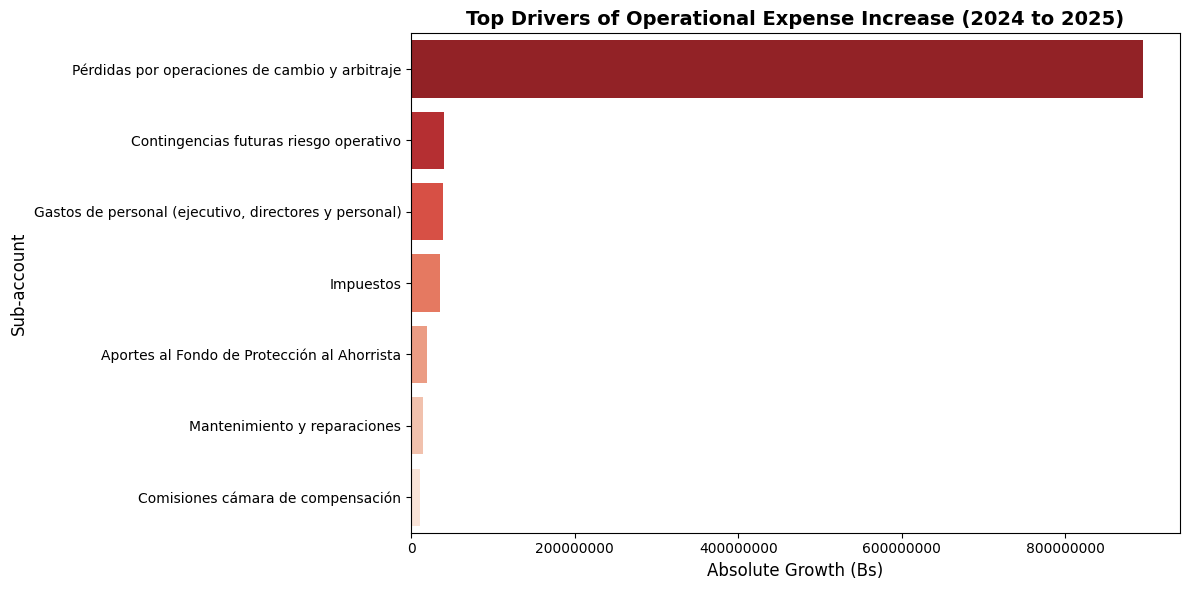

 REPORT: CAUSES OF OPERATIONAL EXPENSE INCREASE (2024 - 2025)
Total Operating Expense Increase: 1,007,764,154 Bs

Key Drivers (Top Sub-accounts):
 • Pérdidas por operaciones de cambio y arbitraje (in 'Gastos Operativos Diversos')
   -> Increased by: 895,301,443 Bs (88.84% of total growth)

 • Contingencias futuras riesgo operativo (in 'Gastos Operativos Diversos')
   -> Increased by: 40,714,100 Bs (4.04% of total growth)

 • Gastos de personal (ejecutivo, directores y personal) (in 'GASTOS DE ADMINISTRACIÓN')
   -> Increased by: 38,517,241 Bs (3.82% of total growth)

 • Impuestos (in 'GASTOS DE ADMINISTRACIÓN')
   -> Increased by: 35,491,971 Bs (3.52% of total growth)

 • Aportes al Fondo de Protección al Ahorrista (in 'Otros Gastos de Administración')
   -> Increased by: 18,933,423 Bs (1.88% of total growth)

ANALYSIS SUMMARY:
The massive increase in the total operational budget from 2024 to 2025 is not due to a widespread structural increase across all areas. Instead, it is highly co

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Calculate the overall total expense growth
total_row = df_cleaned[df_cleaned['CATEGORÍA'].str.contains('TOTAL COSTOS', case=False, na=False)]
if not total_row.empty:
    total_growth_bs = total_row['2025 (Bs)'].values[0] - total_row['2024 (Bs)'].values[0]
else:
    total_growth_bs = sub_accounts['Absolute Growth (Bs)'].sum()

# 2. Get the top items and calculate their impact on the TOTAL growth
top_drivers = sub_accounts.sort_values(by='Absolute Growth (Bs)', ascending=False).head(7).copy()
top_drivers['% of Total Growth'] = (top_drivers['Absolute Growth (Bs)'] / total_growth_bs) * 100

# 3. Create the Visualization
plt.figure(figsize=(12, 6))
sns.barplot(
    data=top_drivers,
    x='Absolute Growth (Bs)',
    y='CONCEPTO / SUBCUENTA',
    hue='CONCEPTO / SUBCUENTA',
    palette='Reds_r',
    legend=False
)
plt.title('Top Drivers of Operational Expense Increase (2024 to 2025)', fontsize=14, fontweight='bold')
plt.xlabel('Absolute Growth (Bs)', fontsize=12)
plt.ylabel('Sub-account', fontsize=12)
plt.ticklabel_format(style='plain', axis='x')
plt.tight_layout()
plt.show()

# 4. Print the analytical report
print("="*75)
print(" REPORT: CAUSES OF OPERATIONAL EXPENSE INCREASE (2024 - 2025)")
print("="*75)
print(f"Total Operating Expense Increase: {total_growth_bs:,.0f} Bs\n")

print("Key Drivers (Top Sub-accounts):")
for _, row in top_drivers.head(5).iterrows():
    print(f" \u2022 {row['CONCEPTO / SUBCUENTA']} (in '{row['CATEGORÍA']}')")
    print(f"   -> Increased by: {row['Absolute Growth (Bs)']:,.0f} Bs ({row['% of Total Growth']:.2f}% of total growth)\n")

print("ANALYSIS SUMMARY:")
print("The massive increase in the total operational budget from 2024 to 2025 is not due to a widespread structural increase across all areas. Instead, it is highly concentrated.")
print("\nThe primary cause is an extreme spike in 'Pérdidas por operaciones de cambio y arbitraje' (Losses on foreign exchange and arbitrage operations), which alone accounts for nearly 90% of the entire organization's expense growth. This strongly suggests that macroeconomic factors, severe exchange rate volatility, or unfavorable currency positions during the period were the main culprits.")
print("\nSecondary increases in general administrative and staff costs (Remuneraciones) play a very distant secondary role in the overall variance.")

In [ ]:
# Calculate YoY percentage growth for individual sub-accounts
df_yoy = sub_accounts.copy()
# Handle potential division by zero
df_yoy['Sub-account YoY Growth (%)'] = (df_yoy['Absolute Growth (Bs)'] / df_yoy[col_2024].replace(0, pd.NA)) * 100

# Merge with the category data to get the Category YoY Growth
yoy_comparison = df_yoy.merge(
    category_grouped[['CATEGORÍA', 'Percentage Growth (%)']],
    on='CATEGORÍA'
).rename(columns={'Percentage Growth (%)': 'Category YoY Growth (%)'})

# Select the top 10 sub-accounts by absolute growth to see their specific growth rates
top_yoy_comparison = yoy_comparison.sort_values(by='Absolute Growth (Bs)', ascending=False).head(10)

print("Year-over-Year (YoY) Percentage Growth: Sub-accounts vs Category Totals")
display(top_yoy_comparison[['CATEGORÍA', 'CONCEPTO / SUBCUENTA', 'Sub-account YoY Growth (%)', 'Category YoY Growth (%)']])

Year-over-Year (YoY) Percentage Growth: Sub-accounts vs Category Totals


2,CATEGORÍA,CONCEPTO / SUBCUENTA,Sub-account YoY Growth (%),Category YoY Growth (%)
6,Gastos Operativos Diversos,Pérdidas por operaciones de cambio y arbitraje,103.381057,88.991286
7,Gastos Operativos Diversos,Contingencias futuras riesgo operativo,111.981132,88.991286
30,GASTOS DE ADMINISTRACIÓN,"Gastos de personal (ejecutivo, directores y pe...",15.182901,19.825603
32,GASTOS DE ADMINISTRACIÓN,Impuestos,50.240639,19.825603
38,Otros Gastos de Administración,Aportes al Fondo de Protección al Ahorrista,23.189921,12.201943
33,GASTOS DE ADMINISTRACIÓN,Mantenimiento y reparaciones,48.104842,19.825603
2,- Detalle comisiones,Comisiones cámara de compensación,72.484604,-34.251550
31,GASTOS DE ADMINISTRACIÓN,Servicios contratados,6.151224,19.825603
39,Otros Gastos de Administración,Propaganda y publicidad,16.366532,12.201943
34,GASTOS DE ADMINISTRACIÓN,Depreciaciones y desvalorización bienes de uso,15.149199,19.825603


In [ ]:
import plotly.express as px
import plotly.graph_objects as go
from IPython.display import display, HTML

# --- Chart 1: Top 5 Expense Categories by Absolute Growth ---
fig1 = px.bar(
    top_5_growth.sort_values('Absolute Growth (Bs)', ascending=True),
    x='Absolute Growth (Bs)',
    y='CATEGORÍA',
    orientation='h',
    title='<b>1. Top 5 Expense Categories by Absolute Growth (2024 - 2025)</b>',
    text_auto='.3s',
    color='Absolute Growth (Bs)',
    color_continuous_scale='Blues'
)
fig1.update_layout(height=400, showlegend=False, coloraxis_showscale=False)

# --- Chart 2: Top Individual Drivers (Sub-accounts) ---
fig2 = px.bar(
    top_drivers.sort_values('Absolute Growth (Bs)', ascending=True),
    x='Absolute Growth (Bs)',
    y='CONCEPTO / SUBCUENTA',
    orientation='h',
    title='<b>2. Top Drivers of Operational Expense Increase (Sub-accounts)</b>',
    text_auto='.3s',
    color='Absolute Growth (Bs)',
    color_continuous_scale='Reds'
)
fig2.update_layout(height=400, showlegend=False, coloraxis_showscale=False)

# --- Chart 3: YoY Percentage Growth Comparison ---
# Sort by Sub-account YoY Growth to make the chart readable
df_chart3 = top_yoy_comparison.sort_values('Sub-account YoY Growth (%)', ascending=True)

fig3 = go.Figure()

# Add Sub-account Growth Bars
fig3.add_trace(go.Bar(
    y=df_chart3['CONCEPTO / SUBCUENTA'],
    x=df_chart3['Sub-account YoY Growth (%)'],
    name='Sub-account YoY Growth (%)',
    orientation='h',
    marker_color='#1f77b4'
))

# Add Category Growth Bars
fig3.add_trace(go.Bar(
    y=df_chart3['CONCEPTO / SUBCUENTA'],
    x=df_chart3['Category YoY Growth (%)'],
    name='Category Overall YoY Growth (%)',
    orientation='h',
    marker_color='#ff7f0e'
))

fig3.update_layout(
    title='<b>3. YoY Percentage Growth: Sub-accounts vs. Their Parent Categories</b>',
    barmode='group',
    height=600,
    legend=dict(orientation="h", yanchor="bottom", y=1.02, xanchor="right", x=1),
    xaxis_title="Growth Percentage (%)"
)

# --- Display Dashboard ---
display(HTML("<h2>Interactive Operational Expenses Dashboard (2024-2025)</h2>"))
display(HTML("<p><i>Hover over the bars to see exact figures. You can also click the legend in Chart 3 to isolate variables.</i></p>"))
fig1.show()
fig2.show()
fig3.show()


In [ ]:
import pandas as pd
import plotly.express as px
from IPython.display import display, HTML

# 1. Select the top 5 drivers from the YoY dataframe
top_5_forecast = df_yoy.sort_values(by='Absolute Growth (Bs)', ascending=False).head(5).copy()

# 2. Calculate the 2026 projection applying the 24-25 growth rate to 2025 actuals
top_5_forecast['2026 (Projected Bs)'] = top_5_forecast[col_2025] * (1 + (top_5_forecast['Sub-account YoY Growth (%)'] / 100))

# 3. Prepare data for the trend line chart by melting it into a long format
trend_data = pd.melt(
    top_5_forecast,
    id_vars=['CONCEPTO / SUBCUENTA'],
    value_vars=[col_2024, col_2025, '2026 (Projected Bs)'],
    var_name='Year',
    value_name='Amount (Bs)'
)

# Clean up the 'Year' labels for better chart readability
trend_data['Year'] = trend_data['Year'].replace({
    col_2024: '2024 (Actual)',
    col_2025: '2025 (Actual)',
    '2026 (Projected Bs)': '2026 (Projected)'
})

# 4. Create the Line Chart
fig_trend = px.line(
    trend_data,
    x='Year',
    y='Amount (Bs)',
    color='CONCEPTO / SUBCUENTA',
    markers=True,
    title='<b>Trend Analysis & 2026 Projection for Top Expense Drivers</b>',
    labels={'Amount (Bs)': 'Expense Amount (Bs)', 'Year': 'Fiscal Year'}
)

fig_trend.update_layout(
    height=500,
    xaxis_title="",
    yaxis_title="Amount (Bs)",
    legend=dict(orientation="h", yanchor="bottom", y=-0.3, xanchor="center", x=0.5)
)

# 5. Display the Data Table and the Chart
display(HTML("<h3>2026 Trend Projection (Assuming 24-25 Growth Rates Persist)</h3>"))
display_cols = ['CATEGORÍA', 'CONCEPTO / SUBCUENTA', col_2024, col_2025, 'Sub-account YoY Growth (%)', '2026 (Projected Bs)']

display(top_5_forecast[display_cols].style.format({
    col_2024: "{:,.0f}",
    col_2025: "{:,.0f}",
    'Sub-account YoY Growth (%)': "{:.2f}%",
    '2026 (Projected Bs)': "{:,.0f}"
}))

fig_trend.show()


2,CATEGORÍA,CONCEPTO / SUBCUENTA,2024 (Bs),2025 (Bs),Sub-account YoY Growth (%),2026 (Projected Bs)
6,Gastos Operativos Diversos,Pérdidas por operaciones de cambio y arbitraje,"866,020,787","1,761,322,230",103.38%,"3,582,195,768"
7,Gastos Operativos Diversos,Contingencias futuras riesgo operativo,"36,358,000","77,072,100",111.98%,"163,378,310"
31,GASTOS DE ADMINISTRACIÓN,"Gastos de personal (ejecutivo, directores y personal)","253,688,280","292,205,521",15.18%,"336,570,797"
33,GASTOS DE ADMINISTRACIÓN,Impuestos,"70,643,948","106,135,919",50.24%,"159,459,283"
39,Otros Gastos de Administración,Aportes al Fondo de Protección al Ahorrista,"81,645,052","100,578,475",23.19%,"123,902,544"


### ⚠️ Projection Disclaimer
This projection represents a baseline *momentum forecast*. It assumes that the exact structural and macroeconomic conditions that drove the 2024-2025 increases (like the ~103% surge in exchange and arbitrage losses) will persist with the exact same intensity into 2026.

If the massive exchange rate losses are a one-time macroeconomic shock, this projection for 2026 will vastly overestimate future costs. A more advanced forecasting model would require historical data spanning 3-5 years to distinguish between long-term trends and temporary economic anomalies.

In [ ]:
import plotly.express as px
import plotly.graph_objects as go
import pandas as pd
from IPython.display import display, HTML

# --- Preparación de Datos Adicionales (Traducción para Tendencias) ---
top_5_forecast_es = df_yoy.sort_values(by='Absolute Growth (Bs)', ascending=False).head(5).copy()
top_5_forecast_es['2026 (Proyectado Bs)'] = top_5_forecast_es[col_2025] * (1 + (top_5_forecast_es['Sub-account YoY Growth (%)'] / 100))

trend_data_es = pd.melt(
    top_5_forecast_es,
    id_vars=['CONCEPTO / SUBCUENTA'],
    value_vars=[col_2024, col_2025, '2026 (Proyectado Bs)'],
    var_name='Año',
    value_name='Monto (Bs)'
)
trend_data_es['Año'] = trend_data_es['Año'].replace({
    col_2024: '2024 (Real)',
    col_2025: '2025 (Real)',
    '2026 (Proyectado Bs)': '2026 (Proyectado)'
})

# --- Gráfico 1: Categorías de Gastos ---
fig1 = px.bar(
    top_5_growth.sort_values('Absolute Growth (Bs)', ascending=True),
    x='Absolute Growth (Bs)',
    y='CATEGORÍA',
    orientation='h',
    title='<b>1. Top 5 Categorías de Gastos por Crecimiento Absoluto (2024 - 2025)</b>',
    text_auto='.3s',
    color='Absolute Growth (Bs)',
    color_continuous_scale='Blues',
    labels={'Absolute Growth (Bs)': 'Crecimiento Absoluto (Bs)'}
)
fig1.update_layout(height=400, showlegend=False, coloraxis_showscale=False)

# --- Gráfico 2: Subcuentas Individuales ---
fig2 = px.bar(
    top_drivers.sort_values('Absolute Growth (Bs)', ascending=True),
    x='Absolute Growth (Bs)',
    y='CONCEPTO / SUBCUENTA',
    orientation='h',
    title='<b>2. Principales Impulsores del Aumento de Gastos (Subcuentas)</b>',
    text_auto='.3s',
    color='Absolute Growth (Bs)',
    color_continuous_scale='Reds',
    labels={'Absolute Growth (Bs)': 'Crecimiento Absoluto (Bs)', 'CONCEPTO / SUBCUENTA': 'Subcuenta'}
)
fig2.update_layout(height=400, showlegend=False, coloraxis_showscale=False)

# --- Gráfico 3: Comparación de Crecimiento Porcentual ---
df_chart3 = top_yoy_comparison.sort_values('Sub-account YoY Growth (%)', ascending=True)
fig3 = go.Figure()
fig3.add_trace(go.Bar(
    y=df_chart3['CONCEPTO / SUBCUENTA'],
    x=df_chart3['Sub-account YoY Growth (%)'],
    name='Crecimiento Interanual Subcuenta (%)',
    orientation='h',
    marker_color='#1f77b4'
))
fig3.add_trace(go.Bar(
    y=df_chart3['CONCEPTO / SUBCUENTA'],
    x=df_chart3['Category YoY Growth (%)'],
    name='Crecimiento Interanual Categoría Macro (%)',
    orientation='h',
    marker_color='#ff7f0e'
))
fig3.update_layout(
    title='<b>3. Crecimiento Interanual (YoY): Subcuentas vs. Categorías Macro</b>',
    barmode='group',
    height=600,
    legend=dict(orientation="h", yanchor="bottom", y=1.02, xanchor="right", x=1),
    xaxis_title="Porcentaje de Crecimiento (%)",
    yaxis_title="Subcuenta"
)

# --- Gráfico 4: Proyección de Tendencia 2026 ---
fig4 = px.line(
    trend_data_es,
    x='Año',
    y='Monto (Bs)',
    color='CONCEPTO / SUBCUENTA',
    markers=True,
    title='<b>4. Análisis de Tendencia y Proyección a 2026 (Principales Impulsores)</b>',
    labels={'Monto (Bs)': 'Monto del Gasto (Bs)', 'CONCEPTO / SUBCUENTA': 'Subcuenta'}
)
fig4.update_layout(
    height=500,
    xaxis_title="",
    yaxis_title="Monto (Bs)",
    legend=dict(orientation="h", yanchor="bottom", y=-0.4, xanchor="center", x=0.5)
)

# --- Construcción del Dashboard y Reporte ---
dashboard_html = """
<div style="font-family: Arial, sans-serif; max-width: 1200px; margin: auto;">
    <h1 style="color: #2c3e50; text-align: center;">📊 Panel de Control: Análisis Integral de Gastos Operativos</h1>
    <p style="text-align: center; color: #7f8c8d;">Evaluación del periodo 2024-2025 y proyección de riesgos hacia 2026</p>
    <hr>

    <h3 style="color: #2980b9;">📑 Reporte Ejecutivo y Razonamiento</h3>
    <p>Este informe detalla las causas fundamentales detrás del aumento de <b>más de 1,000 millones de Bolivianos</b> en el presupuesto operativo, combinando vistas macro y micro, y proyectando el riesgo a futuro.</p>

    <ul>
        <li><b>1. Perspectiva Macro (Gráfico 1):</b> Al analizar las categorías principales, observamos que el aumento no es un problema generalizado de administración o ventas, sino que está altamente concentrado en los <i>"Gastos Operativos Diversos"</i>. Esto descarta ineficiencias operativas tradicionales como causa principal.</li>
        <li><b>2. Causas Raíz (Gráfico 2):</b> Al profundizar a nivel de subcuenta, el origen del problema queda al descubierto: las <i>"Pérdidas por operaciones de cambio y arbitraje"</i> explican por sí solas casi el 90% del incremento total. Esto señala una fuerte exposición a la volatilidad macroeconómica y cambiaria.</li>
        <li><b>3. Magnitud del Impacto (Gráfico 3):</b> La comparación porcentual revela que la cuenta de pérdidas cambiarias creció más de un 103%, arrastrando consigo a toda su categoría. También destaca incrementos inusuales en comisiones e impuestos, que crecieron mucho más rápido que sus respectivas categorías macro.</li>
        <li><b>4. Proyección de Riesgo (Gráfico 4):</b> Basado en el momento actual (crecimiento porcentual 24-25), el análisis de tendencia modela un escenario inercial para 2026. El razonamiento aquí es alertar a la gerencia: si las condiciones macroeconómicas que causaron las pérdidas cambiarias persisten con la misma intensidad, el costo en 2026 se volvería insostenible (proyectado a superar los 3.5 mil millones de Bs).</li>
    </ul>
</div>
"""

# Mostrar el reporte HTML y luego los gráficos
display(HTML(dashboard_html))
fig1.show()
fig2.show()
fig3.show()
fig4.show()


In [ ]:
import base64

# Function to create a standalone HTML file containing the report and all figures
def export_dashboard_to_html(filename='Dashboard_Gastos_Operativos.html'):
    # Generate HTML for figures
    fig1_html = fig1.to_html(full_html=False, include_plotlyjs='cdn')
    fig2_html = fig2.to_html(full_html=False, include_plotlyjs='cdn')
    fig3_html = fig3.to_html(full_html=False, include_plotlyjs='cdn')
    fig4_html = fig4.to_html(full_html=False, include_plotlyjs='cdn')

    # Combine everything into a single HTML document
    full_html = f"""
    <!DOCTYPE html>
    <html>
    <head>
        <meta charset="UTF-8">
        <title>Panel de Control: Análisis de Gastos Operativos</title>
    </head>
    <body>
        {dashboard_html}
        <div style="max-width: 1200px; margin: auto;">
            {fig1_html}
            <br>
            {fig2_html}
            <br>
            {fig3_html}
            <br>
            {fig4_html}
        </div>
    </body>
    </html>
    """

    with open(filename, 'w', encoding='utf-8') as f:
        f.write(full_html)

    print(f"Dashboard successfully exported to {filename}")

    # Provide a download link if running in Colab
    try:
        from google.colab import files
        files.download(filename)
    except ImportError:
        pass

# Execute the function to export and download
export_dashboard_to_html()

Dashboard successfully exported to Dashboard_Gastos_Operativos.html


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>